**ФИО студента:** Михалева Софья Дмитриевна

**Задание:** inpainting

**Группа:** J4251

**Дата сдачи:** 2.11.2026

## Настройка окружения

- Данные: data/inpainting_cube_missed_data.npy
- Модели:
  - models/inpainting_model.pt — **финальная модель** для инференса, обучена на всех известных данных куба;
  - models/inpainting_model_holdout.pt — та же архитектура и настройки, но обучена только на train-блоке. Нужна для честной оценки на test: финальная модель test-строки уже видела.
- RETRAIN = False — веса и история обучения загружаются из models/. True — обе модели обучаются заново (примерно 3.5 ч на GTX 1660 Ti)

In [1]:
import json
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib.patches import Rectangle
from torch.utils.data import DataLoader, Dataset

import SeismicUtils  # Визуализация из материалов курса

SEED = 42


def seed_everything(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


seed_everything(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

DATA_PATH = Path('data/inpainting_cube_missed_data.npy')
MODEL_PATH = Path('models/inpainting_model.pt')                   # Финальная модель (все данные)
HOLDOUT_MODEL_PATH = Path('models/inpainting_model_holdout.pt')   # Модель для оценки на test
HISTORY_PATH = Path('models/inpainting_history.json')             # История обучения обеих моделей
RESTORED_PATH = Path('results/inpainting_restored.npy')           # Восстановленный куб

RETRAIN = False

CFG = dict(
    k=1, stride=1,                      # 2D-вход: один срез axis0 (2.5D здесь не помог, см. «Модель»)
    base=32, up_mode='transpose',       # U-Net: 4 уровня, декодер на ConvTranspose2d
    patch=(352, 192), hole=(213, 103),  # Окно 352 трассы x 192 отсчета, пропуск 213 x 103 - как реальный
    epochs=80, bs=16, lr=1e-3, weight_decay=1e-4,
    n_train=3000, n_eval=400, w_grad=0.5,
)
HOLE = np.s_[:, 368:581, 179:282]
# Блоки по axis0 с зазором (соседние срезы сильно коррелируют)
SPLIT = dict(train=range(0, 400), val=range(416, 496), test=range(500, 580))

print('torch', torch.__version__, '| device', DEVICE, torch.cuda.get_device_name(0) if DEVICE == 'cuda' else '')

torch 2.9.1+cu126 | device cuda NVIDIA GeForce GTX 1660 Ti


## Данные

**Куб и пропуск** Размер 580 × 951 × 462  (axis0 и axis1 латерали, axis2 глубина z). Скрыт «тоннель» [:, 368:581, 179:282]: прямоугольник 213 трасс × 103 отсчета на каждом срезе axis0, через весь axis0, 5% данных. Пропуск заполнен точными нулями, маска известна из задания.

**Нормировка** Из всех значений вычитается среднее и делится на std. Обе величины считаются только по известным вокселам этого же куба

**Self-supervised датасет** Используется только известная часть этого же куба:
- из среза вырезается окно 352 трассы × 192 отсчета, в нем скрывается прямоугольник 213 × 103 — той же формы, что и реальный пропуск, около центра окна со случайным сдвигом (±24 по латерали, ±16 по глубине);
- ответ — исходные значения скрытого прямоугольника;
- окно целиком лежит в известной зоне: по axis1 — вне [368:581], либо срез идет вдоль axis1 по известной трассе.

**Источники окон и аугментации (только train):**
- 50% окон — срезы по axis0, как на инференсе;
- 50% окон — срезы по axis1 внутри train-блока: латерали геологически равноправны, это аугментация и заметно больше разнообразия (по axis0 известных окон шириной 352 мало: пропуск занимает середину axis1);
- флип латерали, масштаб амплитуды ×0.85-1.15

**Разбиение без утечки** — блоками по axis0 с зазором 16 строк: train 0-399, val 416-495, test 500-579. Train — 3000 случайных окон на эпоху. Val и test — по 400 фиксированных окон, только срезы по axis0

In [2]:
cube = np.load(DATA_PATH)
print('shape', cube.shape, cube.dtype)


def hole_mask(shape):
    """True = данных нет."""
    m = np.zeros(shape, dtype=bool)
    m[HOLE] = True
    return m


mask = hole_mask(cube.shape)
print(f'скрыто {mask.mean():.1%}, нулей в пропуске {np.mean(cube[mask] == 0):.0%}, '
      f'нулей вне пропуска {np.mean(cube[~mask] == 0):.2%}')


class Norm:
    def __init__(self, mean, std):
        self.mean, self.std = float(mean), float(std)

    def fwd(self, x):
        return (x - self.mean) / self.std

    def inv(self, x):
        return x * self.std + self.mean

    def __repr__(self):
        return f'Norm(mean={self.mean:.5f}, std={self.std:.5f})'


known = cube[::2][~mask[::2]]
norm = Norm(known.mean(), known.std())
del known
print(norm)


def neighbor_offsets(k, stride):
    return (np.arange(k) - k // 2) * stride


def pack(stack, m):
    """stack: (k, H, W) нормированные срезы, m: (H, W) маска -> x = [k срезов с нулями в пропуске, маска], y, m."""
    stack = np.ascontiguousarray(stack, dtype=np.float32)
    x = np.concatenate([stack * (1 - m)[None], m[None]], 0)
    return (torch.from_numpy(x).float(),
            torch.from_numpy(stack[len(stack) // 2][None].copy()).float(),
            torch.from_numpy(m[None].astype(np.float32)).float())


class InpaintPatches(Dataset):
    """
    Окно (латераль=patch[0], z=patch[1]) с прямоугольным пропуском hole около центра.
    'a0' - срезы cube[i, j0:j0+H, z] (как на инференсе), соседи по axis0;
    'a1' - срезы cube[i0:i0+H, j, z] (аугментация), j - известная трасса, соседи по axis1 только по известным трассам.
    """

    def __init__(self, cube, real_mask, norm, rows0, n_samples, sources=('a0', 'a1'), augment=True,
                 seed=0, fixed=False, k=CFG['k'], stride=CFG['stride'], patch=CFG['patch'], hole=CFG['hole']):
        self.cube, self.norm, self.rows0 = cube, norm, np.asarray(rows0)
        self.n, self.sources, self.augment, self.seed, self.fixed = n_samples, sources, augment, seed, fixed
        self.offs = neighbor_offsets(k, stride)
        self.bad1 = real_mask.any(axis=(0, 2))
        self.clean1 = np.where(~self.bad1)[0]
        self.rng = np.random.default_rng(seed)
        self.ph, self.pw = patch
        self.hh, self.hw = hole
        # Старты окна по axis1, при которых окно целиком в известной зоне
        cs = np.concatenate([[0], np.cumsum(self.bad1)])
        starts = np.arange(len(self.bad1) - self.ph + 1)
        self.j0_ok = starts[cs[starts + self.ph] - cs[starts] == 0]

    def __len__(self):
        return self.n

    def _rng(self, idx):
        # val/test: фиксированный генератор на индекс -> одни и те же окна при каждом проходе
        return np.random.default_rng(self.seed * 100003 + idx) if self.fixed else self.rng

    def _idx0(self, i):
        n0 = self.cube.shape[0]
        idx = i + self.offs
        idx = np.where(idx < 0, -idx, idx)
        return np.where(idx >= n0, 2 * (n0 - 1) - idx, idx)

    def _idx1(self, j):
        idx = j + self.offs
        bad = (idx < 0) | (idx >= len(self.bad1))
        bad |= self.bad1[np.clip(idx, 0, len(self.bad1) - 1)]
        return np.where(bad, j - self.offs, idx)

    def _augment(self, stack, rng):
        if self.augment:
            if rng.random() < 0.5:
                stack = stack[:, ::-1]
            if rng.random() < 0.5:
                stack = stack[::-1]
            stack = stack * rng.uniform(0.85, 1.15)
        return stack

    def __getitem__(self, idx):
        rng = self._rng(idx)
        src = self.sources[rng.integers(len(self.sources))]
        z0 = rng.integers(0, self.cube.shape[2] - self.pw + 1)
        zs = slice(z0, z0 + self.pw)
        if src == 'a0':
            i = rng.choice(self.rows0)
            j0 = rng.choice(self.j0_ok)
            win = self.cube[self._idx0(i), j0:j0 + self.ph, zs]
        else:
            j = rng.choice(self.clean1)
            lo, hi = self.rows0.min(), self.rows0.max() + 1
            i0 = rng.integers(lo, hi - self.ph + 1)
            win = self.cube[i0:i0 + self.ph, self._idx1(j), zs].transpose(1, 0, 2)
        stack = self._augment(self.norm.fwd(np.array(win, dtype=np.float32)), rng)
        # Пропуск: около центра со случайным смещением
        cy = (self.ph - self.hh) // 2 + rng.integers(-24, 25)
        cx = (self.pw - self.hw) // 2 + rng.integers(-16, 17)
        cy = int(np.clip(cy, 8, self.ph - self.hh - 8))
        cx = int(np.clip(cx, 8, self.pw - self.hw - 8))
        m = np.zeros(stack.shape[1:], dtype=np.float32)
        m[cy:cy + self.hh, cx:cx + self.hw] = 1
        return pack(stack, m)


def make_datasets(full=False):
    tr_rows = range(0, cube.shape[0]) if full else SPLIT['train']
    tr = InpaintPatches(cube, mask, norm, tr_rows, CFG['n_train'], ('a0', 'a1'), True, SEED, False)
    va = InpaintPatches(cube, mask, norm, SPLIT['val'], CFG['n_eval'], ('a0',), False, 1000 + SEED, True)
    te = InpaintPatches(cube, mask, norm, SPLIT['test'], CFG['n_eval'], ('a0',), False, 2000 + SEED, True)
    return tr, va, te


def draw_hole(a, m2, lw=1):
    """Красная рамка вокруг прямоугольного пропуска m2 (латераль, z) на картинке img.T."""
    rows, cols = np.where(m2.any(1))[0], np.where(m2.any(0))[0]
    a.add_patch(Rectangle((rows[0] - .5, cols[0] - .5), len(rows), len(cols), fill=False, edgecolor='r', lw=lw))


train_ds, val_ds, test_ds = make_datasets()
x, y, m = test_ds[0]
print('x', tuple(x.shape), '(срез + маска) | y', tuple(y.shape), '| m', tuple(m.shape))
print('стартов окна по axis1 в известной зоне:', len(train_ds.j0_ok))

shape (580, 951, 462) float32
скрыто 5.0%, нулей в пропуске 100%, нулей вне пропуска 0.00%
Norm(mean=0.49996, std=0.03833)
x (2, 352, 192) (срез + маска) | y (1, 352, 192) | m (1, 352, 192)
стартов окна по axis1 в известной зоне: 36


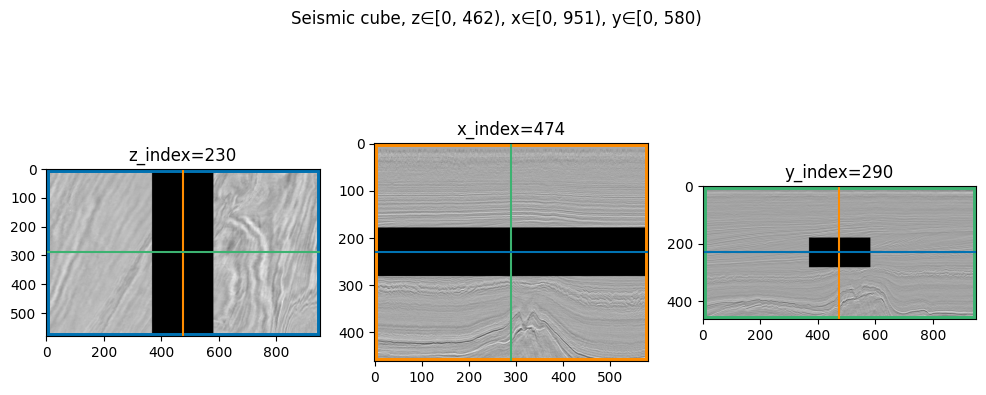

In [3]:
# Куб с пропуском в трех проекциях
SeismicUtils.visualize_three_plots(cube=cube, z_index=230, x_index=474, y_index=290)

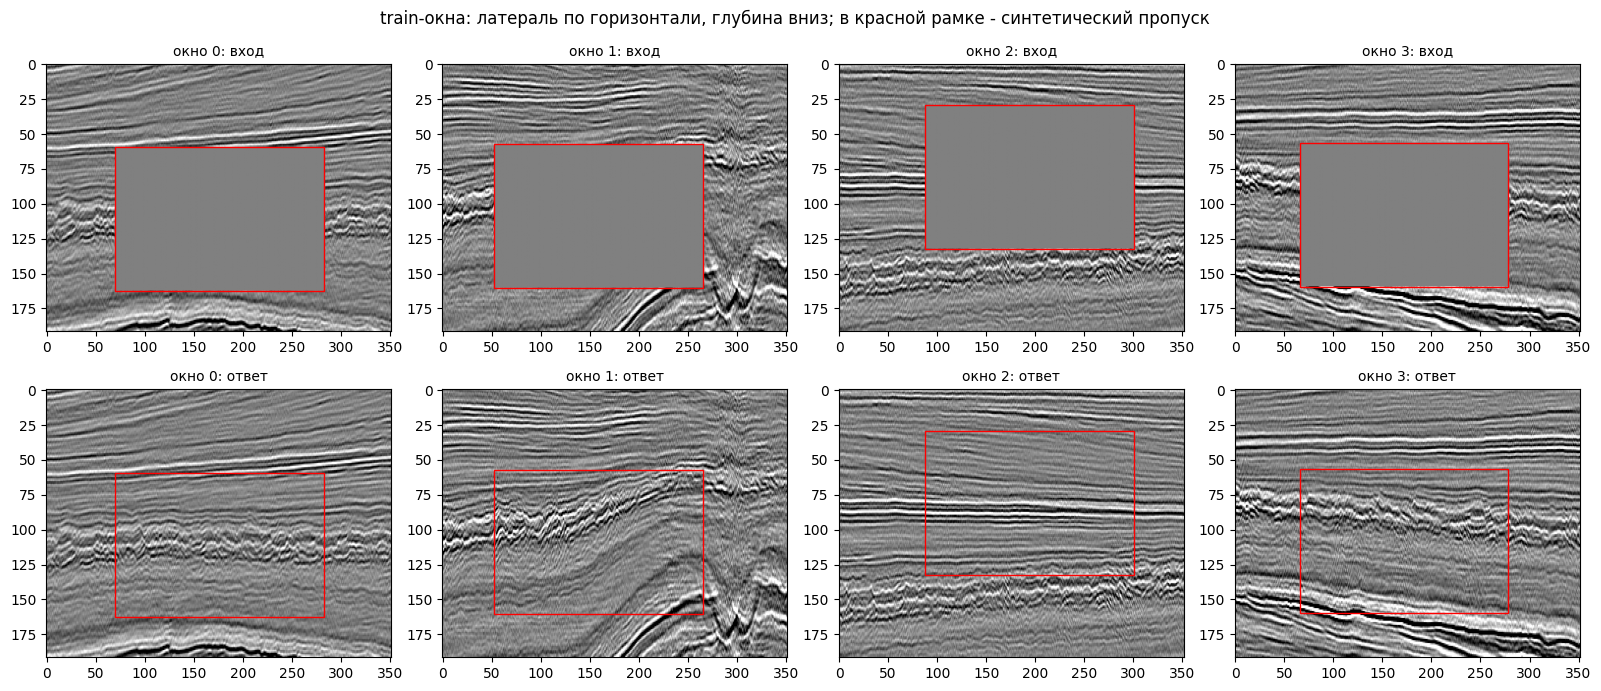

In [4]:
# Примеры обучающих окон: вход (пропуск обнулен) и ответ
fig, ax = plt.subplots(2, 4, figsize=(16, 7))
for c in range(4):
    x, y, m = train_ds[c]
    for r, (img, t) in enumerate([(x[CFG['k'] // 2], 'вход'), (y[0], 'ответ')]):
        ax[r, c].imshow(img.numpy().T, cmap='gray', vmin=-2.5, vmax=2.5, aspect='auto')
        draw_hole(ax[r, c], m[0].numpy() > 0.5)
        ax[r, c].set_title(f'окно {c}: {t}', fontsize=10)
fig.suptitle('train-окна: латераль по горизонтали, глубина вниз; в красной рамке - синтетический пропуск')
plt.tight_layout()
plt.show()

## Модель

**U-Net**, 4 уровня энкодера, base = 32 канала, блоки DoubleConv (Conv3×3–BN–ReLU × 2), ~7.8 млн параметров.
- **Вход** — 2 канала: срез с обнуленным пропуском и маска пропуска.
- **Выход** — 1 канал: срез целиком. Задача решается как регрессия значений.
- **Итоговая заливка:** известные значения берутся из входа без изменений, из выхода модели только пропуск.
- **Декодер:** ConvTranspose2d ×2. Вариант с билинейным апсемплингом (класс UpConv, up_mode='upsample') тоже проверялся.

Выбор сделан по val R среди вариантов: U-Net с ConvTranspose (k = 1), с апсемплингом (k = 1), с апсемплингом и 2.5D-входом (k = 5 соседних срезов axis0) и GAN (pix2pix) поверх U-Net. Лучший val R — у простого варианта с ConvTranspose: 0.443 против 0.434 (апсемплинг) и 0.431 (2.5D). На test порядок тот же. 2.5D не помогает, потому что пропуск проходит через весь axis0: у соседних срезов тот же пропуск, а их известная часть почти повторяет центральный срез. Полное сравнение в README репозитория https://github.com/Sofredsun/cv_seysmorazvedka

In [5]:
class DoubleConv(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class UpConv(nn.Module):
    """Билинейный апсемплинг x2 + свертка 3x3 (вариант up_mode='upsample')."""

    def __init__(self, cin, cout):
        super().__init__()
        self.conv = nn.Conv2d(cin, cout, 3, padding=1)

    def forward(self, x):
        return self.conv(F.interpolate(x, scale_factor=2, mode='bilinear', align_corners=False))


class UNet(nn.Module):
    def __init__(self, in_ch=CFG['k'] + 1, base=CFG['base'], depth=4, up_mode=CFG['up_mode']):
        super().__init__()
        chs = [base * 2 ** i for i in range(depth + 1)]
        self.downs = nn.ModuleList()
        c = in_ch
        for ch in chs[:-1]:
            self.downs.append(DoubleConv(c, ch))
            c = ch
        self.bottleneck = DoubleConv(chs[-2], chs[-1])
        self.ups, self.decs = nn.ModuleList(), nn.ModuleList()
        for ch in reversed(chs[:-1]):
            self.ups.append(nn.ConvTranspose2d(ch * 2, ch, 2, stride=2) if up_mode == 'transpose'
                            else UpConv(ch * 2, ch))
            self.decs.append(DoubleConv(ch * 2, ch))
        self.head = nn.Conv2d(chs[0], 1, 1)
        self.mult = 2 ** depth

    def forward(self, x):
        H, W = x.shape[-2:]
        ph, pw = (-H) % self.mult, (-W) % self.mult
        if ph or pw:
            x = F.pad(x, (0, pw, 0, ph), mode='reflect')
        skips = []
        for d in self.downs:
            x = d(x)
            skips.append(x)
            x = F.max_pool2d(x, 2)
        x = self.bottleneck(x)
        for up, dec, s in zip(self.ups, self.decs, reversed(skips)):
            x = dec(torch.cat([up(x), s], 1))
        return self.head(x)[..., :H, :W]


def composite(known, pred, m):
    return known * (1 - m) + pred * m


def load_model(path):
    ck = torch.load(path, map_location=DEVICE)
    model = UNet(in_ch=ck['k'] + 1, base=ck['base'], up_mode=ck['up_mode']).to(DEVICE)
    model.load_state_dict(ck['state_dict'])
    model.eval()
    return model, ck


print(f"параметров: {sum(p.numel() for p in UNet().parameters()) / 1e6:.2f} млн")

параметров: 7.76 млн


## Обучение модели

**Loss** — по пропуску: L1 + 0.5 · L1 разницы градиентов по глубине и по латерали. Градиентная часть удерживает слоистость

**Метрики** — R (корреляция Пирсона) по пропуску, в двух вариантах:
- **R_mean** — R внутри каждого пропуска, усредненный по окнам;
- **R_global** — один R по всем вокселам всех пропусков

**Оптимизация:**
- AdamW, lr = 1e-3, weight decay = 1e-4;
- OneCycleLR на 80 эпох, batch 16;
- fp32 — в fp16 на GTX 1660 Ti получались NaN.

**Две модели одной конфигурации:**
1. **holdout** — обучается на train-блоке. Лучшая эпоха выбирается по val R, по ней же выбирался вариант модели. Её test R — честная оценка качества.
2. **финальная** — та же конфигурация и те же 80 эпох, но train — все строки axis0, сохраняется последняя эпоха. Так больше данных и тот же режим обучения. Ее «val» пересекается с train, это только контроль сходимости.

Holdout-модель обучалась до того, как в лог добавила R_global, поэтому в ее сохраненной истории по эпохам есть только val R_mean. R_global на test для нее считается ниже. При RETRAIN = True в истории обе метрики

In [6]:
def pearson_r_torch(pred, target, m, eps=1e-6):
    """R по маске для каждого элемента батча -> (B,)."""
    m, p, t = m.flatten(1), pred.flatten(1), target.flatten(1)
    n = m.sum(1).clamp_min(1)
    pc = (p - ((p * m).sum(1) / n)[:, None]) * m
    tc = (t - ((t * m).sum(1) / n)[:, None]) * m
    return (pc * tc).sum(1) / (torch.sqrt((pc ** 2).sum(1) * (tc ** 2).sum(1)) + eps)


class HoleLoss(nn.Module):
    def __init__(self, w_g=CFG['w_grad']):
        super().__init__()
        self.w_g = w_g

    def forward(self, pred, tgt, m):
        n = m.sum().clamp_min(1)
        l1 = ((pred - tgt).abs() * m).sum() / n
        gz = ((torch.diff(pred, dim=-1) - torch.diff(tgt, dim=-1)).abs() * m[..., 1:]).sum() / n
        gx = ((torch.diff(pred, dim=-2) - torch.diff(tgt, dim=-2)).abs() * m[..., 1:, :]).sum() / n
        with torch.no_grad():
            r = pearson_r_torch(pred, tgt, m).mean()
        return l1 + self.w_g * (gz + gx), r.item()


class RAcc:
    """R_mean (по окнам) и R_global (по всем вокселам пропусков) - потоково."""

    def __init__(self):
        self.rs, self.s = [], np.zeros(6)  # n, Σp, Σt, Σp², Σt², Σpt

    def add(self, p, y, m):
        self.rs.append(pearson_r_torch(p, y, m).cpu())
        sel = m > 0.5
        pv, tv = p[sel].double(), y[sel].double()
        self.s += torch.stack([pv.new_tensor(pv.numel()), pv.sum(), tv.sum(), (pv * pv).sum(),
                               (tv * tv).sum(), (pv * tv).sum()]).cpu().numpy()

    def result(self):
        n, sp, st, spp, stt, spt = self.s
        rg = (spt - sp * st / n) / (np.sqrt((spp - sp * sp / n) * (stt - st * st / n)) + 1e-12)
        return float(torch.cat(self.rs).mean()), float(rg)


@torch.no_grad()
def evaluate(model, loader, crit):
    model.eval()
    tot, acc = 0.0, RAcc()
    for x, y, m in loader:
        x, y, m = x.to(DEVICE), y.to(DEVICE), m.to(DEVICE)
        p = model(x)
        tot += crit(p, y, m)[0].item() * x.size(0)
        acc.add(p, y, m)
    model.train()
    return (tot / len(loader.dataset), *acc.result())


def train_model(full, out_path):
    """full=False: train-блок, сохраняется лучшая по val R эпоха; full=True: все строки, последняя эпоха."""
    seed_everything(SEED)
    tr_ds, va_ds, _ = make_datasets(full=full)
    tr = DataLoader(tr_ds, batch_size=CFG['bs'])
    va = DataLoader(va_ds, batch_size=CFG['bs'])
    model = UNet().to(DEVICE)
    crit = HoleLoss()
    opt = torch.optim.AdamW(model.parameters(), lr=CFG['lr'], weight_decay=CFG['weight_decay'])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG['lr'], total_steps=CFG['epochs'] * len(tr))
    meta = {'base': CFG['base'], 'k': CFG['k'], 'stride': CFG['stride'], 'up_mode': CFG['up_mode'],
            'norm': [norm.mean, norm.std], 'full': full}
    vk = 'ctrl' if full else 'val'
    hist = {'train_loss': [], 'train_r': [], f'{vk}_loss': [], f'{vk}_r': [], f'{vk}_r_global': []}
    best, best_ep = -1.0, None
    for ep in range(1, CFG['epochs'] + 1):
        t0, tl, trs = time.time(), 0.0, []
        for x, y, m in tr:
            x, y, m = x.to(DEVICE), y.to(DEVICE), m.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            loss, r = crit(model(x), y, m)
            loss.backward()
            opt.step()
            sched.step()
            tl += loss.item() * x.size(0)
            trs.append(r)
        vl, vr, vrg = evaluate(model, va, crit)
        for key, v in [('train_loss', tl / len(tr_ds)), ('train_r', float(np.mean(trs))),
                       (f'{vk}_loss', vl), (f'{vk}_r', vr), (f'{vk}_r_global', vrg)]:
            hist[key].append(v)
        if not full and vr > best:
            best, best_ep = vr, ep
            torch.save({'state_dict': model.state_dict(), 'epoch': ep, **meta}, out_path)
        print(f'ep {ep:3d} train {hist["train_loss"][-1]:.4f} r {hist["train_r"][-1]:.4f} | '
              f'{vk} {vl:.4f} r {vr:.4f} rg {vrg:.4f} | {time.time() - t0:.0f}s', flush=True)
    if full:
        torch.save({'state_dict': model.state_dict(), 'epoch': CFG['epochs'], **meta}, out_path)
    return {'hist': hist, 'best_epoch': best_ep}


if RETRAIN:
    MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
    history = {'holdout': train_model(full=False, out_path=HOLDOUT_MODEL_PATH),
               'full': train_model(full=True, out_path=MODEL_PATH)}
    json.dump(history, open(HISTORY_PATH, 'w'), indent=1)
else:
    history = json.load(open(HISTORY_PATH))
print('лучшая эпоха holdout-модели по val R:', history['holdout']['best_epoch'])

лучшая эпоха holdout-модели по val R: 54


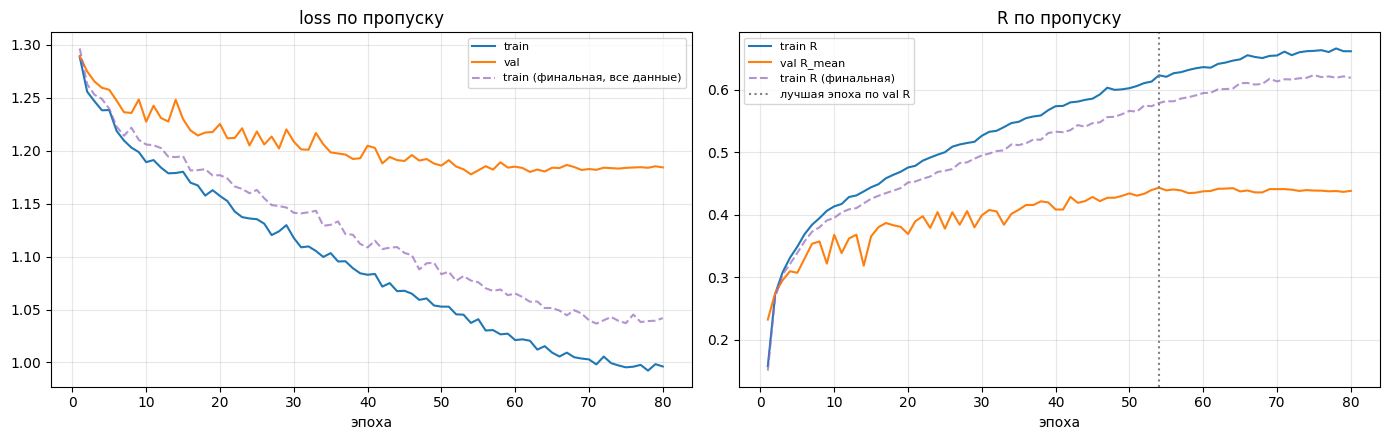

In [7]:
# Графики обучения: train + val по loss и R
h, hf = history['holdout']['hist'], history['full']['hist']
ep = np.arange(1, len(h['train_loss']) + 1)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(ep, h['train_loss'], label='train')
ax[0].plot(ep, h['val_loss'], label='val')
ax[0].plot(ep, hf['train_loss'], '--', color='C4', alpha=.7, label='train (финальная, все данные)')
ax[1].plot(ep, h['train_r'], label='train R')
ax[1].plot(ep, h['val_r'], label='val R_mean')
if 'val_r_global' in h:
    ax[1].plot(ep, h['val_r_global'], label='val R_global')
ax[1].plot(ep, hf['train_r'], '--', color='C4', alpha=.7, label='train R (финальная)')
ax[1].axvline(history['holdout']['best_epoch'], color='gray', ls=':', label='лучшая эпоха по val R')
ax[0].set_title('loss по пропуску')
ax[1].set_title('R по пропуску')
for a in ax:
    a.set_xlabel('эпоха')
    a.grid(alpha=.3)
    a.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [8]:
# Лог обучения по эпохам (из сохранённой истории; при RETRAIN = True он же печатается во время обучения)
def print_log(hist, vk, best=None):
    has_rg = f'{vk}_r_global' in hist
    print(f"{'эп':>3} | {'train loss':>10} {'train R':>8} | {vk + ' loss':>10} {vk + ' R':>8}"
          + (f" {vk + ' R_gl':>10}" if has_rg else ''))
    for i in range(len(hist['train_loss'])):
        mark = '  <- лучшая по val R' if best == i + 1 else ''
        rg = f" {hist[vk + '_r_global'][i]:>10.4f}" if has_rg else ''
        print(f"{i + 1:>3} | {hist['train_loss'][i]:>10.4f} {hist['train_r'][i]:>8.4f} | "
              f"{hist[vk + '_loss'][i]:>10.4f} {hist[vk + '_r'][i]:>8.4f}{rg}{mark}")


print('holdout-модель: train - строки 0-399, val - строки 416-495')
print_log(history['holdout']['hist'], 'val', history['holdout']['best_epoch'])
print()
print('финальная модель: train - все строки; ctrl = val-строки, они входят в train -> только контроль сходимости')
print_log(history['full']['hist'], 'ctrl')

holdout-модель: train - строки 0-399, val - строки 416-495
 эп | train loss  train R |   val loss    val R
  1 |     1.2887   0.1574 |     1.2896   0.2320
  2 |     1.2559   0.2733 |     1.2750   0.2748
  3 |     1.2467   0.3077 |     1.2654   0.2950
  4 |     1.2383   0.3311 |     1.2595   0.3095
  5 |     1.2384   0.3489 |     1.2576   0.3071
  6 |     1.2187   0.3692 |     1.2473   0.3303
  7 |     1.2096   0.3841 |     1.2364   0.3536
  8 |     1.2029   0.3946 |     1.2357   0.3572
  9 |     1.1987   0.4063 |     1.2484   0.3217
 10 |     1.1893   0.4135 |     1.2275   0.3679
 11 |     1.1912   0.4173 |     1.2426   0.3386
 12 |     1.1841   0.4285 |     1.2310   0.3620
 13 |     1.1787   0.4310 |     1.2276   0.3681
 14 |     1.1790   0.4374 |     1.2482   0.3184
 15 |     1.1801   0.4441 |     1.2299   0.3655
 16 |     1.1698   0.4490 |     1.2193   0.3802
 17 |     1.1672   0.4585 |     1.2144   0.3868
 18 |     1.1576   0.4640 |     1.2172   0.3832
 19 |     1.1628   0.4689 |  

## Тестирование модели

**Test-блок:** строки axis0 500-579, 400 фиксированных окон с синтетическим пропуском. Ни в обучении, ни в выборе модели он не участвовал. Оценивается holdout-модель.

**TTA** — усреднение с предсказанием по окну, отраженному по латерали (и обратно). Пропуск стоит около центра окна, поэтому при флипе он остается пропуском той же формы.

**Бейзлайн без обучения** — линейная интерполяция по латерали между краями пропуска на каждой глубине

In [9]:
@torch.no_grad()
def predict(model, x, tta=True):
    k = CFG['k']
    preds = [model(x)]
    if tta:
        if k > 1:
            preds.append(model(torch.cat([x[:, :k].flip(1), x[:, k:]], 1)))  # Флип стопки соседних срезов
        preds.append(model(x.flip(2)).flip(2))                               # Флип латерали
    return torch.stack(preds).mean(0)


def baseline_linear(y, m):
    """Линейная интерполяция по латерали между краями пропуска на каждой глубине."""
    out = y.clone()
    for b in range(y.shape[0]):
        mm = m[b, 0] > 0.5
        rows, cols = torch.where(mm.any(1))[0], torch.where(mm.any(0))[0]
        r0, r1 = rows.min().item() - 1, rows.max().item() + 1
        t = torch.arange(1, r1 - r0, dtype=y.dtype)[:, None] / (r1 - r0)
        out[b, 0, r0 + 1:r1, cols] = y[b, 0, r0, cols] * (1 - t) + y[b, 0, r1, cols] * t
    return out


test_loader = DataLoader(test_ds, batch_size=CFG['bs'])
holdout, ck_h = load_model(HOLDOUT_MODEL_PATH)
print('holdout-модель: эпоха', ck_h['epoch'])

accs = {'бейзлайн (линейная)': RAcc(), 'U-Net': RAcc(), 'U-Net + TTA': RAcc()}
for x, y, m in test_loader:
    accs['бейзлайн (линейная)'].add(baseline_linear(y, m), y, m)
    x, y, m = x.to(DEVICE), y.to(DEVICE), m.to(DEVICE)
    accs['U-Net'].add(predict(holdout, x, tta=False), y, m)
    accs['U-Net + TTA'].add(predict(holdout, x, tta=True), y, m)

test_results = {name: dict(zip(['R_mean', 'R_global'], a.result())) for name, a in accs.items()}
print(f"{'модель':<24}{'R_mean':>8}{'R_global':>10}")
for name, r in test_results.items():
    print(f"{name:<24}{r['R_mean']:>8.4f}{r['R_global']:>10.4f}")

holdout-модель: эпоха 54
модель                    R_mean  R_global
бейзлайн (линейная)       0.1100    0.1027
U-Net                     0.3208    0.3300
U-Net + TTA               0.3318    0.3417


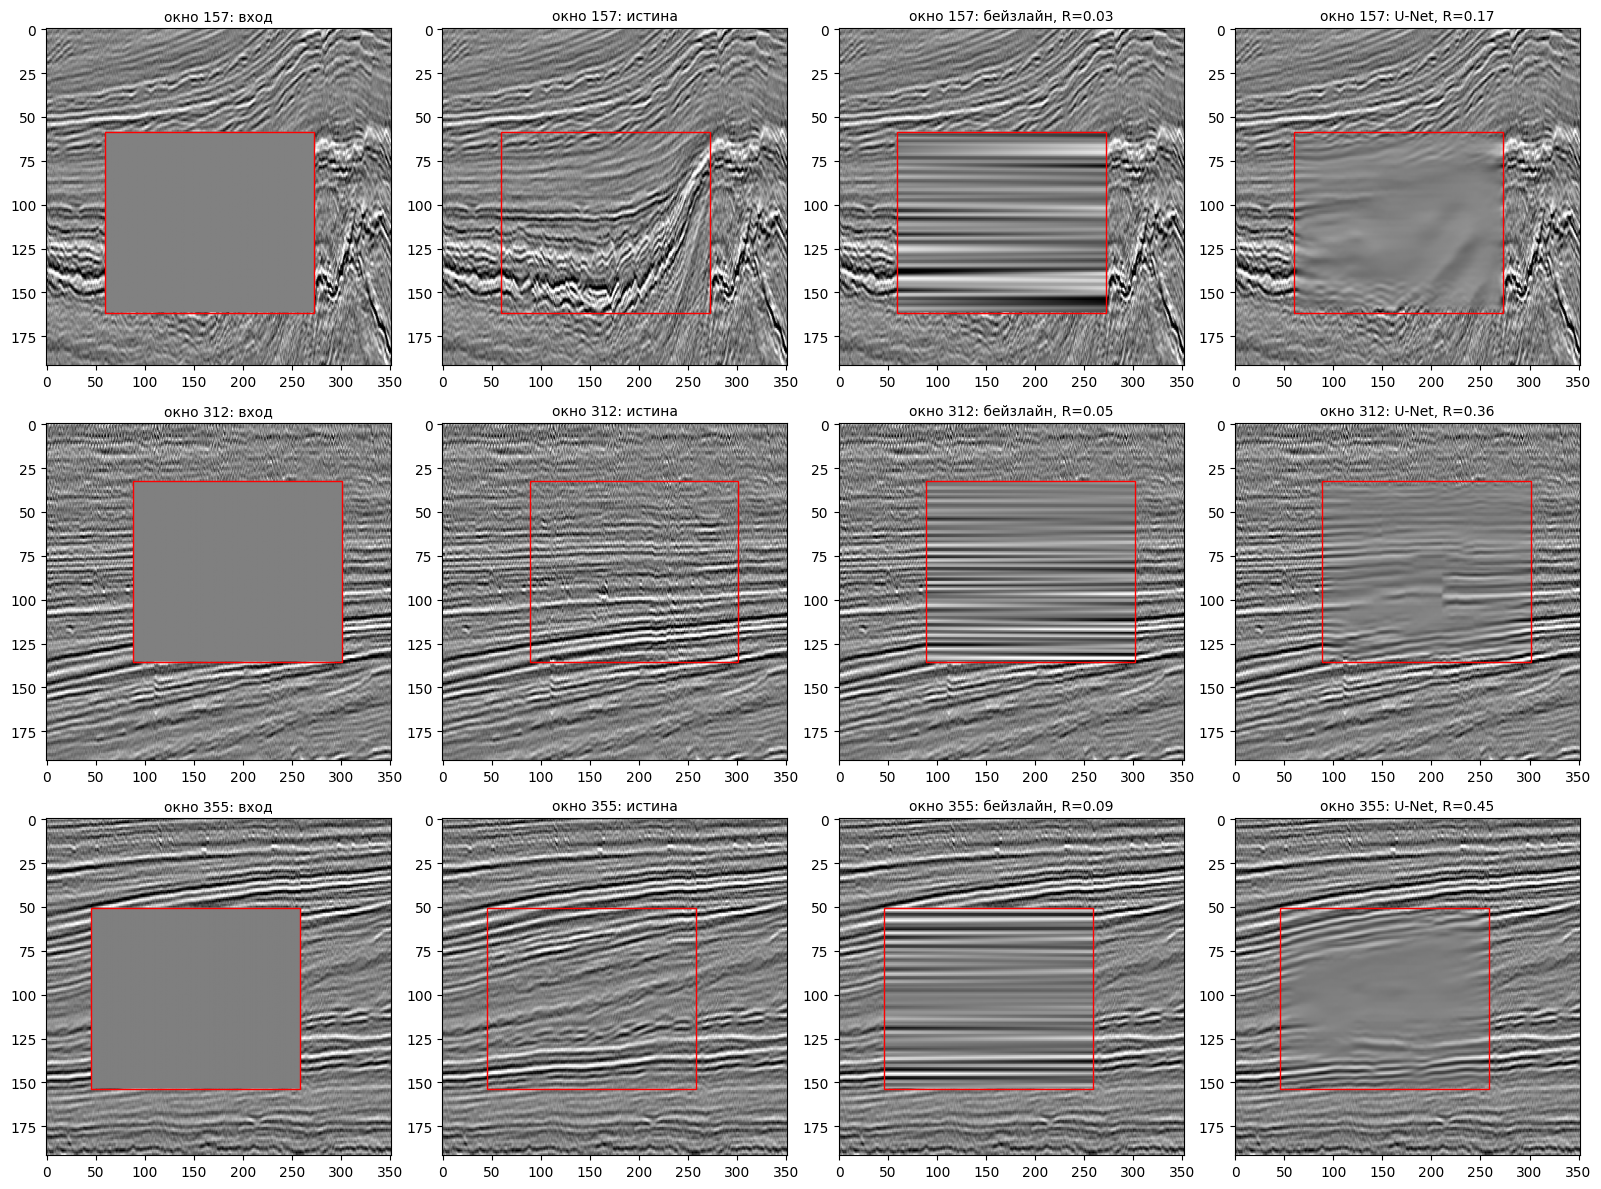

In [10]:
# Примеры с test-блока: вход / истина / бейзлайн / U-Net.
# Окна 157, 312, 355 - с R U-Net на 15%, 50% и 85% квантилях по test-блоку
idxs = [157, 312, 355]
fig, ax = plt.subplots(len(idxs), 4, figsize=(16, 4 * len(idxs)))
for row, i in enumerate(idxs):
    x, y, m = (t[None] for t in test_ds[i])
    p = composite(y, predict(holdout, x.to(DEVICE)).cpu(), m)
    b = baseline_linear(y, m)
    lo, hi = np.percentile(y.numpy(), [1, 99])
    panels = [((y * (1 - m))[0, 0], 'вход'), (y[0, 0], 'истина'),
              (b[0, 0], f'бейзлайн, R={pearson_r_torch(b, y, m).item():.2f}'),
              (p[0, 0], f'U-Net, R={pearson_r_torch(p, y, m).item():.2f}')]
    for c, (img, title) in enumerate(panels):
        ax[row, c].imshow(img.numpy().T, cmap='gray', vmin=lo, vmax=hi, aspect='auto')
        draw_hole(ax[row, c], m[0, 0].numpy() > 0.5)
        ax[row, c].set_title(f'окно {i}: {title}', fontsize=10)
plt.tight_layout()
plt.show()

**Итог на test:**
- U-Net в 3 раза лучше бейзлайна: R_global = 0.33-0.34 против 0.10. Линейная интерполяция через 213 трасс почти ничего не угадывает: наклонные и изогнутые границы она превращает в горизонтальные полосы.
- Центр пропуска удален от известных данных на ~100 трасс и ~50 отсчетов. Модель уверенно продолжает отражения у краев пропуска, а к центру заливка становится бледной и гладкой. С L1 модель предсказывает «условное среднее», std заливки ≈ 0.43 от данных. Задача оказалась гораздо труднее outpainting

## Инференс модели

Используется **финальная модель**. Для каждого из 580 срезов axis0 повторяется то же, что на обучении:
1. Вырезается окно 352 × 192 вокруг пропуска: [i, 299:651, 135:327], пропуск — в его центре, как в обучающих окнах.
2. Предсказание — среднее по исходному окну и окну, отраженному по латерали (TTA)
3. Предсказание переводится обратно из нормированных единиц и вставляется только в пропуск. Известные значения куба не меняются.

In [11]:
@torch.no_grad()
def predict_windows(model, stacks, m, bs=8):
    """stacks: (N, k, H, W) нормированные стопки, m: (H, W) маска -> (N, H, W)."""
    out = np.empty((stacks.shape[0],) + stacks.shape[2:], dtype=np.float32)
    mt = torch.from_numpy(m.astype(np.float32)).to(DEVICE)
    for s in range(0, stacks.shape[0], bs):
        xs = torch.from_numpy(np.ascontiguousarray(stacks[s:s + bs])).to(DEVICE)
        x = torch.cat([xs * (1 - mt), mt.expand(xs.shape[0], 1, *mt.shape)], 1)
        out[s:s + bs] = predict(model, x)[:, 0].cpu().numpy()
    return out


def stacks_axis0(cube_n, offs, js, zs):
    """Для каждого среза i: стопка соседей по axis0 (с отражением у границ) в окне (js, zs) -> (N, k, H, W)."""
    n0 = cube_n.shape[0]
    idx = np.arange(n0)[:, None] + offs[None]
    idx = np.where(idx < 0, -idx, idx)
    idx = np.where(idx >= n0, 2 * (n0 - 1) - idx, idx)
    return cube_n[:, js, zs][idx]


def restore_cube(cube, model, ck, patch=CFG['patch']):
    m_cube = hole_mask(cube.shape)
    offs = neighbor_offsets(ck['k'], ck['stride'])
    nrm = Norm(*ck['norm'])
    cube_n = nrm.fwd(cube.astype(np.float32))
    restored = cube.copy()
    # Окно с пропуском в центре
    js_h, zs_h = np.where(m_cube[0].any(1))[0], np.where(m_cube[0].any(0))[0]
    j0 = js_h[0] - (patch[0] - len(js_h)) // 2
    z0 = zs_h[0] - (patch[1] - len(zs_h)) // 2
    js, zs = slice(j0, j0 + patch[0]), slice(z0, z0 + patch[1])
    print(f'окно инференса: axis1 [{js.start}:{js.stop}], z [{zs.start}:{zs.stop}]')
    m = m_cube[0, js, zs]
    pred = predict_windows(model, stacks_axis0(cube_n, offs, js, zs), m)
    restored[:, js, zs][:, m] = nrm.inv(pred[:, m])
    return restored


final_model, ck_f = load_model(MODEL_PATH)
print('финальная модель:', {k: v for k, v in ck_f.items() if k != 'state_dict'})
t0 = time.time()
restored = restore_cube(cube, final_model, ck_f)
print(f'инференс {time.time() - t0:.0f} с')

финальная модель: {'epoch': 80, 'base': 32, 'k': 1, 'stride': 1, 'up_mode': 'transpose', 'norm': [0.4999571740627289, 0.038330044597387314], 'full': True}
окно инференса: axis1 [299:651], z [135:327]
инференс 10 с


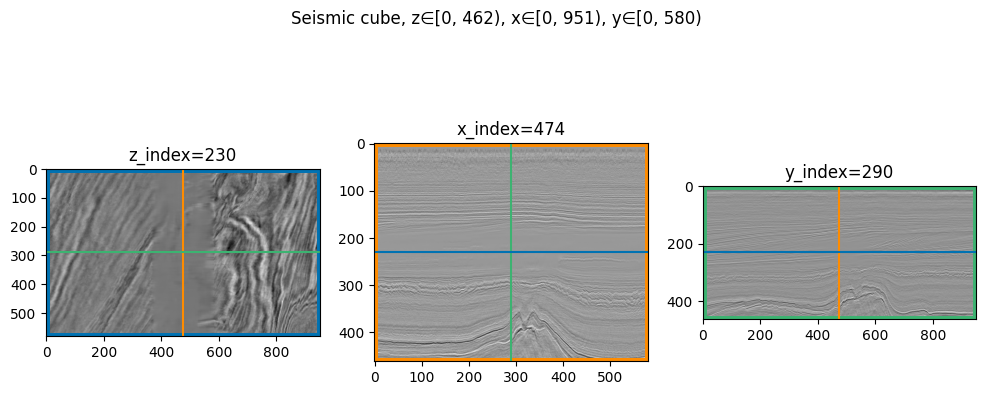

In [12]:
SeismicUtils.visualize_three_plots(cube=restored, z_index=230, x_index=474, y_index=290)

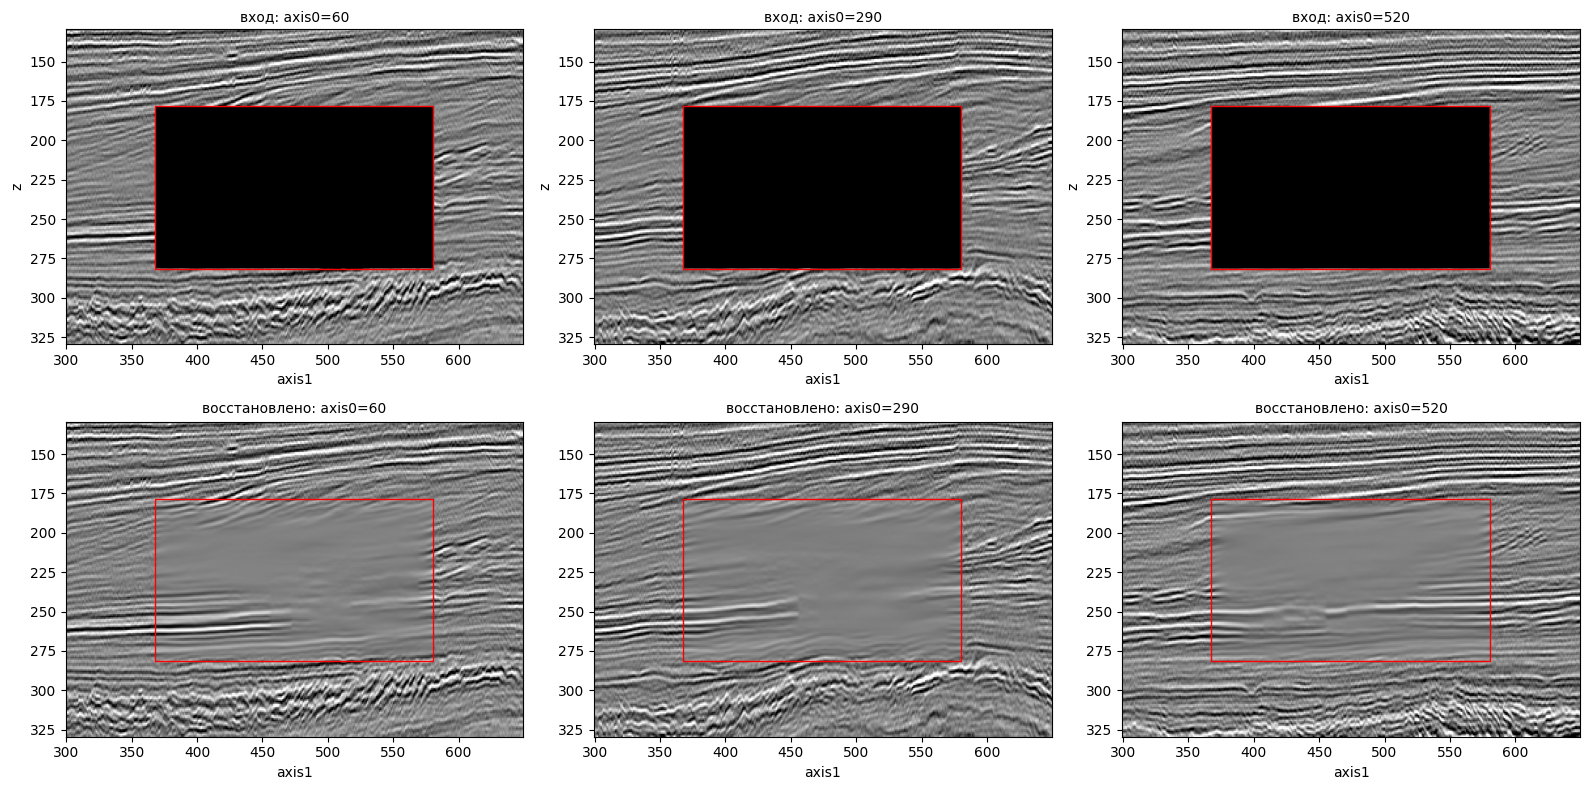

In [13]:
# Окрестность пропуска крупно на трёх срезах axis0 (красная рамка - граница пропуска)
j0, j1, z0, z1 = 300, 650, 130, 330
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for c, i0 in enumerate([60, 290, 520]):
    lo, hi = np.percentile(cube[i0][~mask[i0]], [1, 99])
    for r, (src, name) in enumerate([(cube, 'вход'), (restored, 'восстановлено')]):
        a = ax[r, c]
        a.imshow(src[i0, j0:j1, z0:z1].T, cmap='gray', vmin=lo, vmax=hi, aspect='auto',
                 extent=(j0 - .5, j1 - .5, z1 - .5, z0 - .5))
        a.add_patch(Rectangle((368 - .5, 179 - .5), 213, 103, fill=False, edgecolor='r', lw=1))
        a.set_title(f'{name}: axis0={i0}', fontsize=10)
        a.set_xlabel('axis1')
    ax[0, c].set_ylabel('z')
plt.tight_layout()
plt.show()

## Блок сохранения артефактов

- **Модель.** Веса сохраняются через torch.save в словаре вместе с конфигурацией (k, stride, base, up_mode) и параметрами нормировки (norm). Этого достаточно, чтобы восстановить модель функцией load_model из блока «Модель». При RETRAIN = True файлы перезаписываются в блоке обучения.
- **Восстановленный куб** сохраняется в .npy, в исходном типе float32 и в исходных единицах.
- **Проверки перед сохранением:** размер совпадает со входом, NaN и inf нет, известные значения не изменены, в пропуске не осталось нулей

In [14]:
assert restored.shape == cube.shape, (restored.shape, cube.shape)
assert restored.dtype == cube.dtype
assert np.isfinite(restored).all(), 'NaN/inf в результате'
assert np.array_equal(restored[~mask], cube[~mask]), 'известные значения изменены'
assert not (restored[mask] == 0).any(), 'в пропуске остались нули'
filled, known = restored[mask], cube[~mask][::97]
print(f'shape {restored.shape} == input {cube.shape}, dtype {restored.dtype}')
print(f'известные данные: mean {known.mean():.4f} std {known.std():.4f} | '
      f'заливка: mean {filled.mean():.4f} std {filled.std():.4f}')

RESTORED_PATH.parent.mkdir(parents=True, exist_ok=True)
np.save(RESTORED_PATH, restored)
print('куб сохранён:', RESTORED_PATH, f'{RESTORED_PATH.stat().st_size / 1e6:.0f} МБ')

print('модель:', MODEL_PATH, f'{MODEL_PATH.stat().st_size / 1e6:.1f} МБ, ключи:', list(ck_f))
reloaded, _ = load_model(MODEL_PATH)
assert all(torch.equal(a, b) for a, b in zip(reloaded.state_dict().values(), final_model.state_dict().values()))
print('модель загружается и совпадает с использованной на инференсе')

shape (580, 951, 462) == input (580, 951, 462), dtype float32
известные данные: mean 0.5000 std 0.0383 | заливка: mean 0.5002 std 0.0171
куб сохранён: results\inpainting_restored.npy 1019 МБ
модель: models\inpainting_model.pt 31.1 МБ, ключи: ['state_dict', 'epoch', 'base', 'k', 'stride', 'up_mode', 'norm', 'full']
модель загружается и совпадает с использованной на инференсе
